# Cellphone Price Range Prediction

## Project Overview
This project develops a machine learning classification system to predict the price range of a mobile phone from its technical specifications.

## Business Objective
Bob has started a new mobile company and wants to compete with large brands. He does not know how to price the phones his company creates. The objective is to analyze the mobile-phone sales data, identify which specifications are associated with higher prices, compare multiple classification models, select the best-performing model, and show how it can help Bob price products and expand the business.

## Project Tasks
1. Perform a complete exploratory data analysis of the mobile phone dataset.
2. Build a predictive model for the price range (0 = low, 1 = medium, 2 = high, 3 = very high cost).
3. Prepare an analysis report on how the model helps expand the business, including feature importance.
4. Compare multiple machine learning models and recommend the best model for production.
5. Document the major data challenges and the techniques used to address them.

> **Important:** The model predicts a price *range* (0 to 3), not the exact selling price. It is based on historical patterns in the supplied dataset and does not account for brand value, marketing, or market timing.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [38]:
data = pd.read_csv("datasets_11167_15520_train.csv")
print("Shape:", data.shape)
data.head()

Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [39]:
    data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [40]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


In [41]:
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [42]:
data["price_range"].value_counts().sort_index()

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

**Observations:** The dataset contains 2,000 mobile phones with 20 features and the target `price_range`. There are no missing values or duplicate rows, and all columns are numeric. The four price classes are perfectly balanced (500 each). `sc_w` and `px_height` contain zeros, which need investigation.

# Data cleaning

In [43]:
cols_to_check = ["px_height", "sc_w", "fc", "pc", "m_dep", "mobile_wt", "int_memory", "talk_time"]
for c in cols_to_check:
    print(f"{c:12s} zeros: {(data[c] == 0).sum()}")

px_height    zeros: 2
sc_w         zeros: 180
fc           zeros: 474
pc           zeros: 101
m_dep        zeros: 0
mobile_wt    zeros: 0
int_memory   zeros: 0
talk_time    zeros: 0


In [44]:
data[data["sc_w"] == 0]["price_range"].value_counts().sort_index()

price_range
0    49
1    48
2    44
3    39
Name: count, dtype: int64

In [45]:
df = data.copy()      

for col in ["px_height", "sc_w"]:
    median_val = int(round(df.loc[df[col] != 0, col].median()))
    df.loc[df[col] == 0, col] = median_val
    print(f"{col}: zeros replaced with median = {median_val}")

px_height: zeros replaced with median = 566
sc_w: zeros replaced with median = 6


In [46]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

num_cols = ["battery_power", "clock_speed", "fc", "int_memory", "m_dep", "mobile_wt",
            "n_cores", "pc", "px_height", "px_width", "ram", "sc_h", "sc_w", "talk_time"]
pd.Series({c: count_outliers(df[c]) for c in num_cols}).sort_values(ascending=False)

fc               18
px_height         2
battery_power     0
clock_speed       0
int_memory        0
m_dep             0
mobile_wt         0
n_cores           0
pc                0
px_width          0
ram               0
sc_h              0
sc_w              0
talk_time         0
dtype: int64

**Cleaning decisions:** `px_height` (2 rows) and `sc_w` (180 rows) contained zeros, which are physically impossible. The `sc_w` zeros were spread evenly across price classes, so they were treated as data-entry gaps and replaced with the median of the non-zero values. Zeros in `fc` and `pc` were kept because a phone can have no camera. A few high `fc` values were kept as genuine specifications.

# EDA

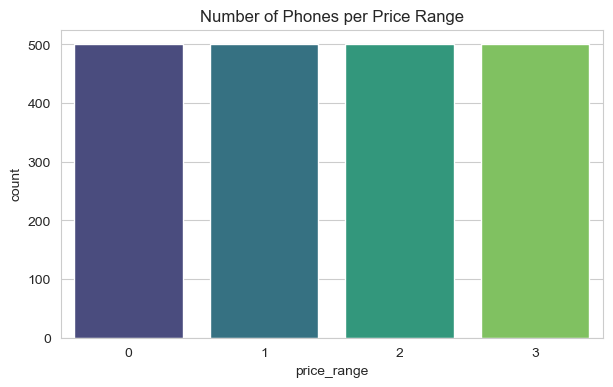

In [47]:
# Target distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="price_range", palette="viridis")
plt.title("Number of Phones per Price Range")
plt.show()

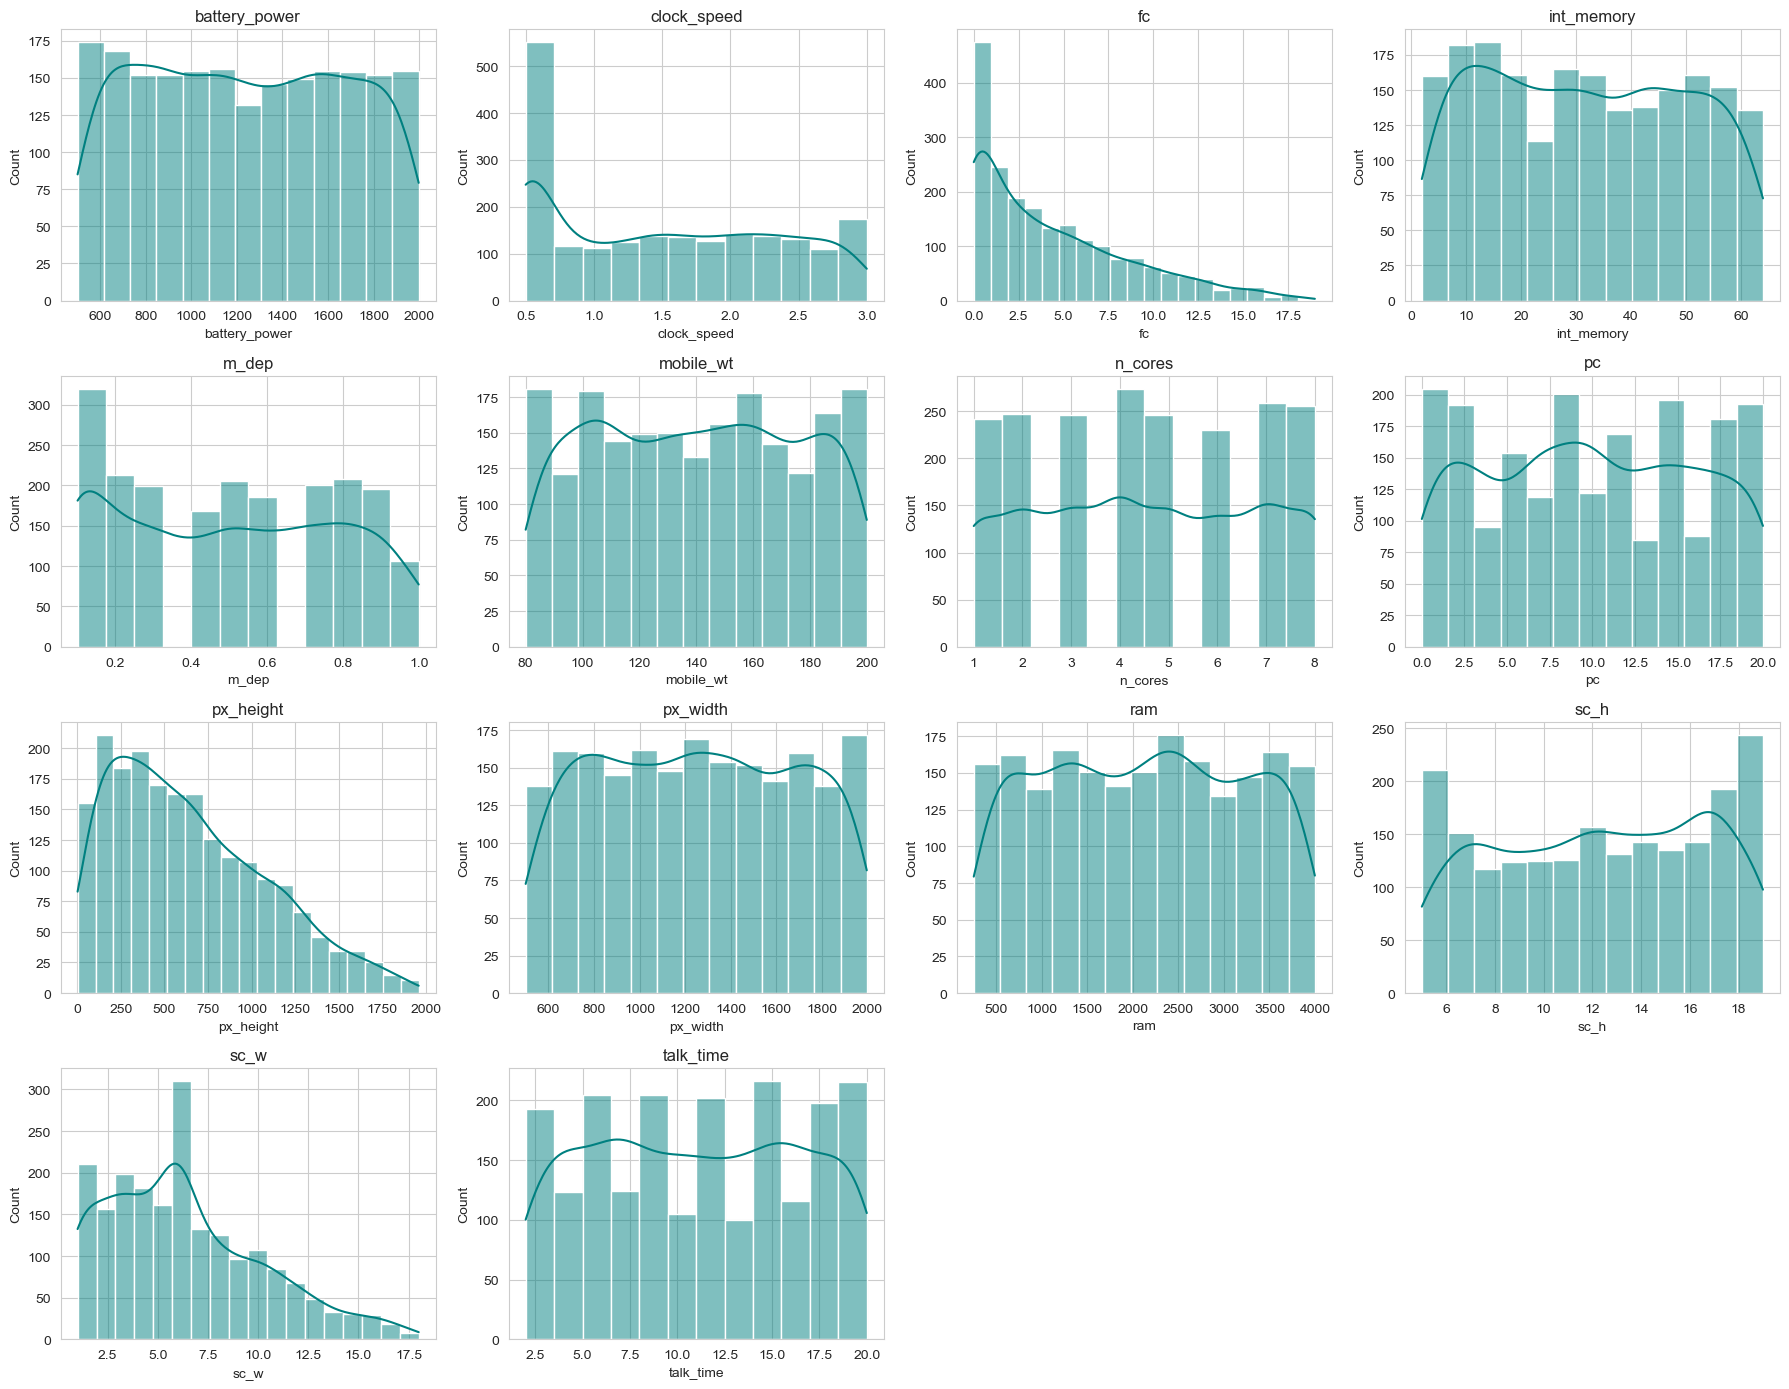

In [48]:
# Distribution of numeric features
num_cols = ["battery_power", "clock_speed", "fc", "int_memory", "m_dep", "mobile_wt",
            "n_cores", "pc", "px_height", "px_width", "ram", "sc_h", "sc_w", "talk_time"]

fig, ax = plt.subplots(4, 4, figsize=(18, 14))
ax = ax.ravel()
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=ax[i], color="teal")
    ax[i].set_title(c)
for j in range(len(num_cols), len(ax)):
    ax[j].axis("off")                      
plt.tight_layout()
plt.show()

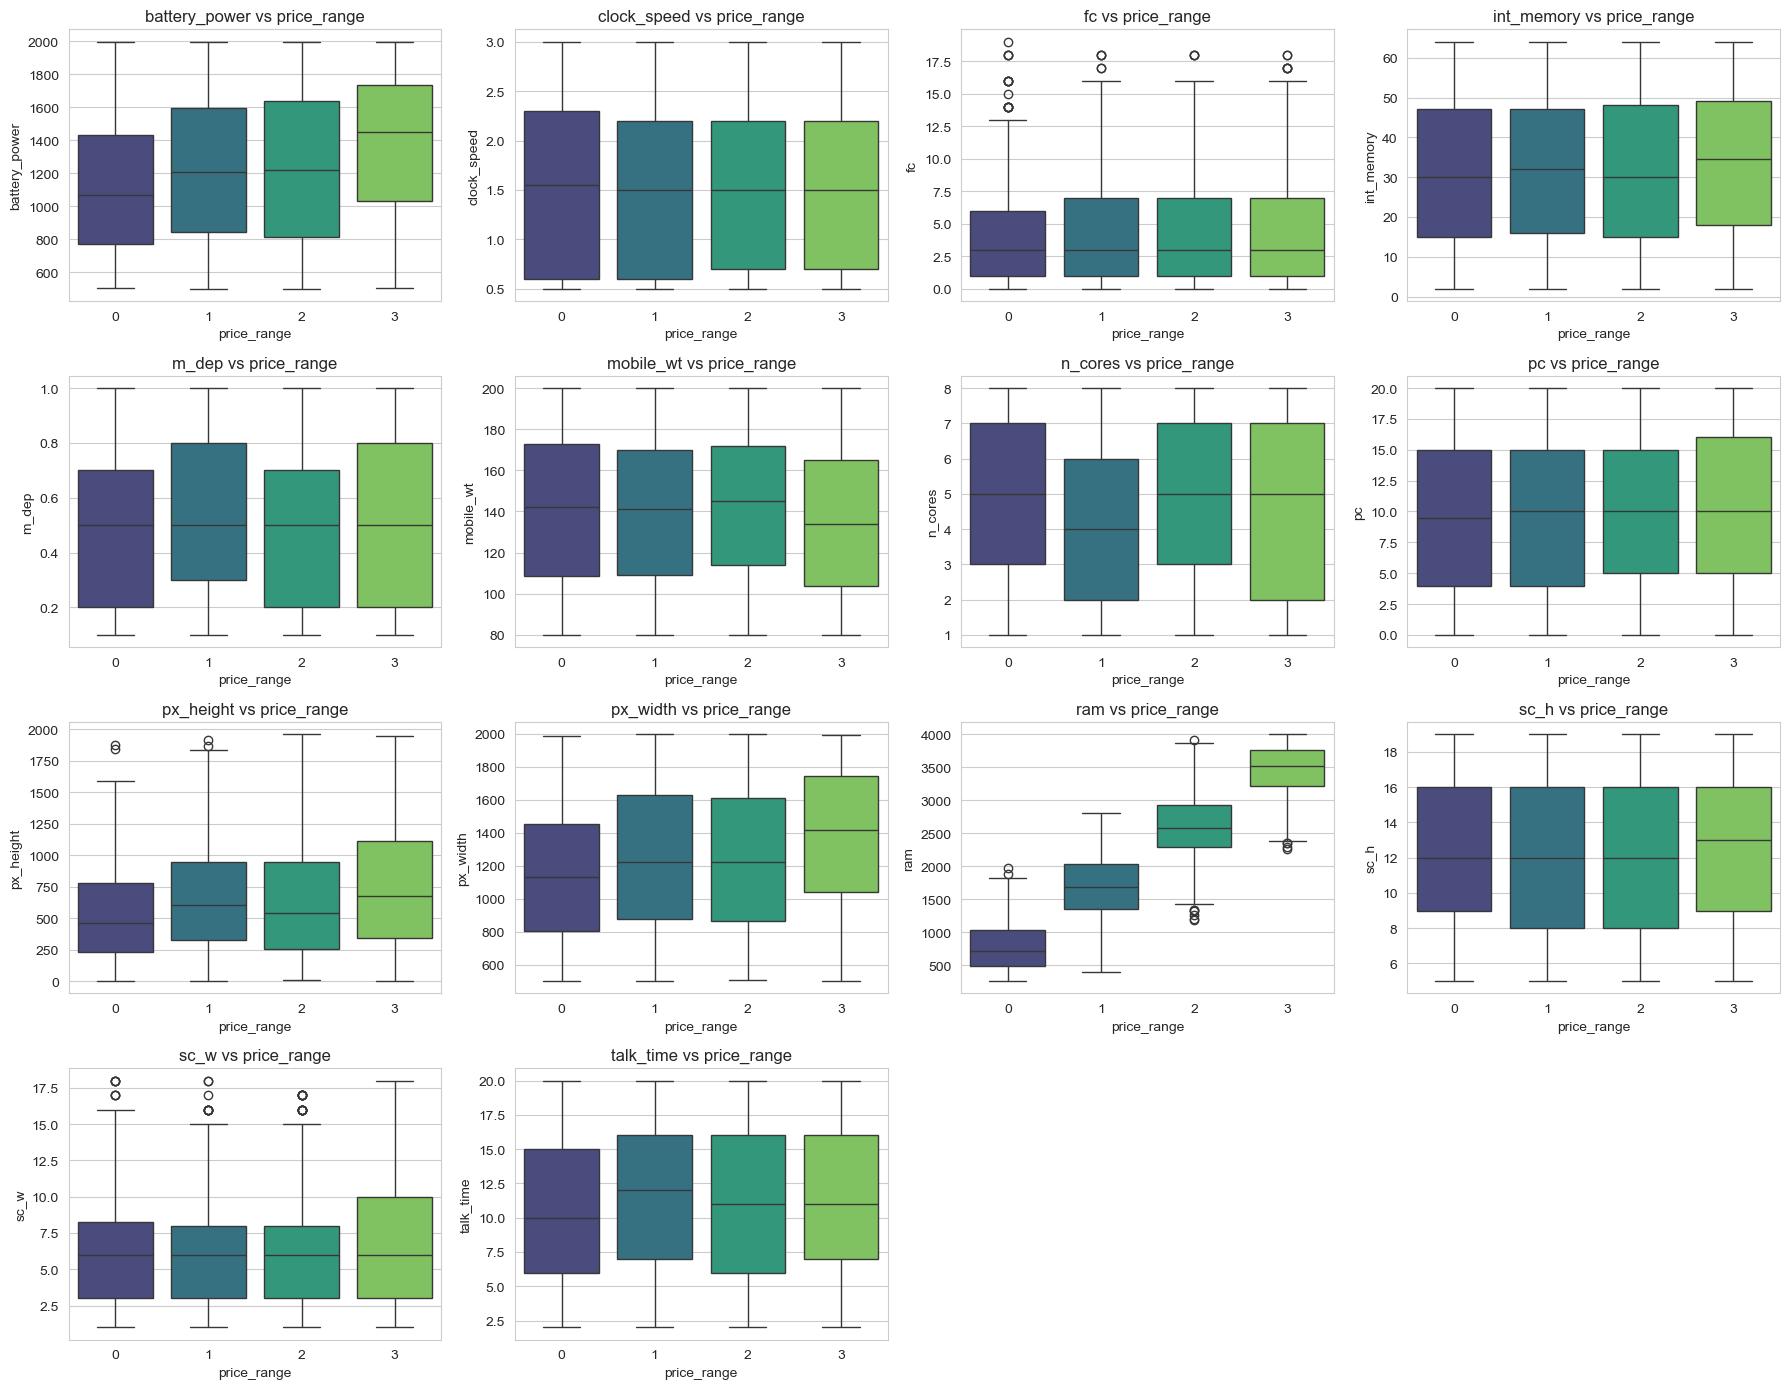

In [49]:
# Numeric feature vs Price range
fig, ax = plt.subplots(4, 4, figsize=(18, 14))
ax = ax.ravel()
for i, c in enumerate(num_cols):
    sns.boxplot(data=df, x="price_range", y=c, ax=ax[i], palette="viridis")
    ax[i].set_title(f"{c} vs price_range")
for j in range(len(num_cols), len(ax)):
    ax[j].axis("off")
plt.tight_layout()
plt.show()

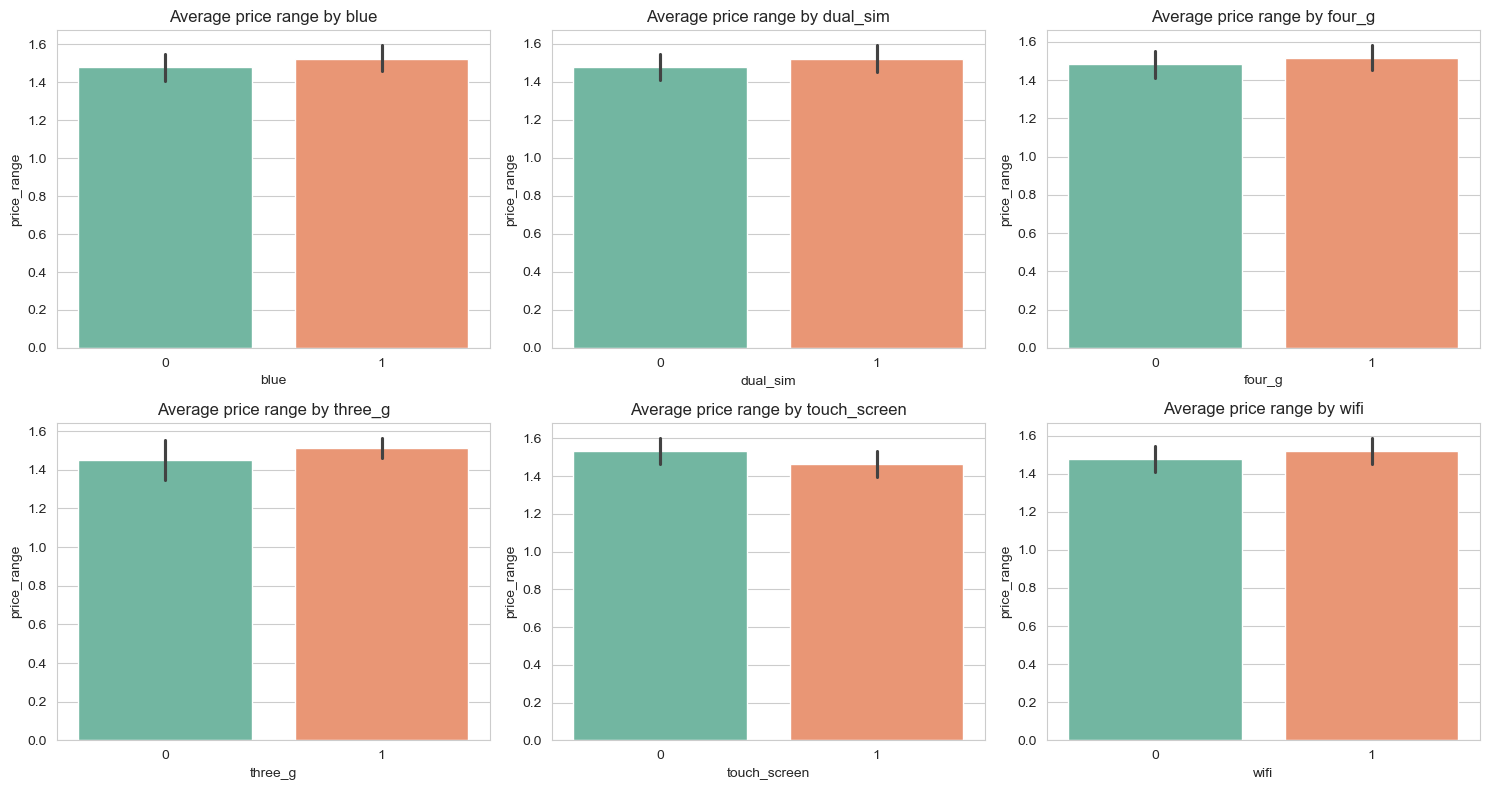

In [50]:
# Yes/no features vs price
binary_cols = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.ravel()
for i, c in enumerate(binary_cols):
    sns.barplot(data=df, x=c, y="price_range", ax=ax[i], palette="Set2")
    ax[i].set_title(f"Average price range by {c}")
plt.tight_layout()
plt.show()

In [51]:
df.groupby("price_range")[binary_cols].mean().round(2)

,blue,dual_sim,four_g,three_g,touch_screen,wifi
price_range,,,,,,
0,0.49,0.50,0.52,0.75,0.52,0.50
1,0.49,0.51,0.52,0.76,0.52,0.50
2,0.49,0.50,0.49,0.77,0.47,0.50
3,0.52,0.53,0.55,0.77,0.50,0.52


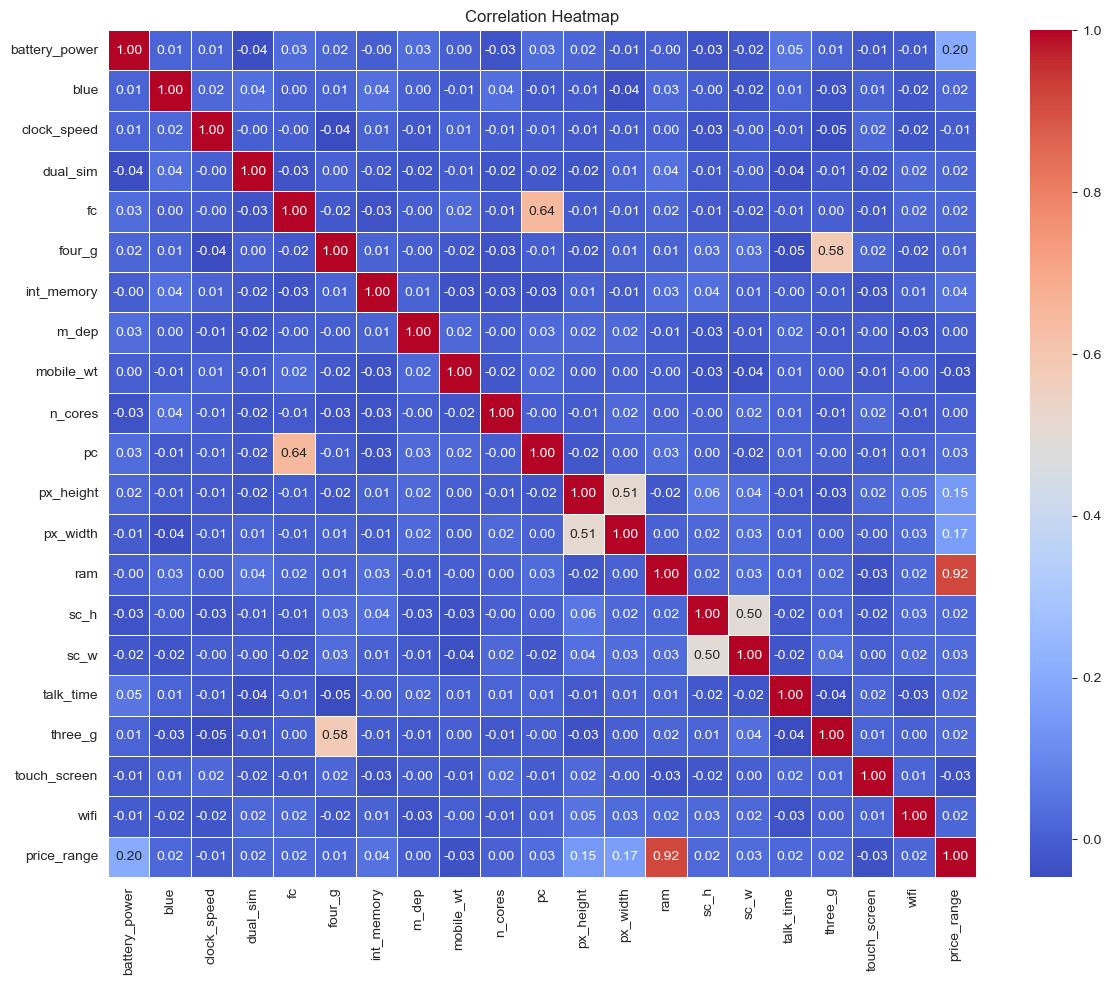

In [52]:
# Correlation heatmap
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [53]:
df.corr()["price_range"].drop("price_range").sort_values(ascending=False).round(3)

ram              0.917
battery_power    0.201
px_width         0.166
px_height        0.150
int_memory       0.044
pc               0.034
sc_w             0.031
three_g          0.024
sc_h             0.023
fc               0.022
talk_time        0.022
blue             0.021
wifi             0.019
dual_sim         0.017
four_g           0.015
n_cores          0.004
m_dep            0.001
clock_speed     -0.007
mobile_wt       -0.030
touch_screen    -0.030
Name: price_range, dtype: float64

In [54]:
# Checking  multicollinearity between features
corr_pairs = df.drop(columns="price_range").corr().abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1].sort_values(ascending=False).iloc[::2]   # remove duplicate pairs
corr_pairs.head(6).round(3)

fc         pc               0.645
three_g    four_g           0.584
px_width   px_height        0.512
sc_h       sc_w             0.498
px_height  sc_h             0.059
talk_time  battery_power    0.053
dtype: float64

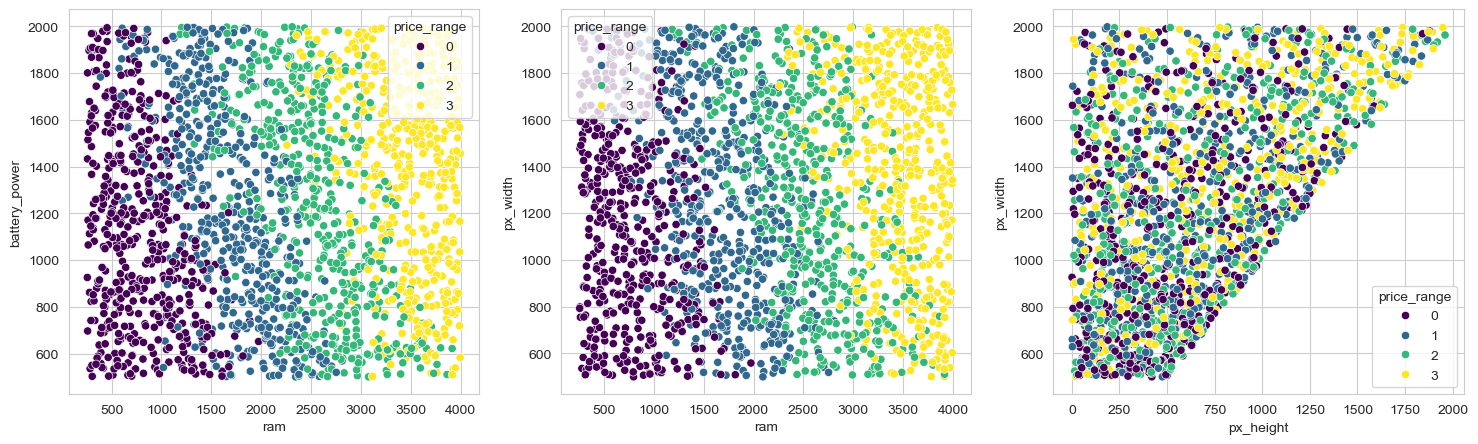

In [55]:
# RAM vs the other strong features
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="ram", y="battery_power", hue="price_range", palette="viridis", ax=ax[0])
sns.scatterplot(data=df, x="ram", y="px_width",      hue="price_range", palette="viridis", ax=ax[1])
sns.scatterplot(data=df, x="px_height", y="px_width", hue="price_range", palette="viridis", ax=ax[2])
plt.show()

## Key Findings from EDA
- The dataset has 2,000 phones with no missing values or duplicates, and a perfectly balanced target (500 per class).
- **RAM is by far the strongest driver of price range** (correlation 0.92); higher RAM means a higher price class.
- Battery power and screen resolution (pixel width/height) have weak positive relationships with price.
- Bluetooth, Wi-Fi, 3G, 4G, dual SIM and touch screen show almost no relationship with price in this data.
- Clock speed, number of cores, weight, depth and talk time are also weak predictors.
- Impossible zeros were found in `sc_w` (180 rows) and `px_height` (2 rows) and were replaced with the median.
- No serious multicollinearity (highest feature-to-feature correlation about 0.65).

# Feature engineering and selection

In [56]:
df_model = df.copy()     
df_model["px_total"]    = df_model["px_height"] * df_model["px_width"]  
df_model["screen_area"] = df_model["sc_h"] * df_model["sc_w"]            

X = df_model.drop(columns=["price_range"])     
y = df_model["price_range"]                    
print(X.shape)

(2000, 22)


In [57]:
# Stratified train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_train.value_counts().sort_index().to_dict())

Train: (1600, 22) | Test: (400, 22)
{0: 400, 1: 400, 2: 400, 3: 400}


In [26]:
# Imports and a helper function
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
import time

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted = {}      # every trained model is stored here

def evaluate(name, model, fit=True):
    """Train (optionally) and return all metrics for one model."""
    t0 = time.time()
    if fit:
        model.fit(X_train, y_train)
    fit_time = (time.time() - t0) if fit else np.nan
    fitted[name] = model

    pred_train = model.predict(X_train)
    pred_test  = model.predict(X_test)
    proba_test = model.predict_proba(X_test)

    return {
        "Model": name,
        "Train Acc": accuracy_score(y_train, pred_train),
        "Test Acc":  accuracy_score(y_test, pred_test),
        "CV Acc":    cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy").mean(),
        "Precision": precision_score(y_test, pred_test, average="macro"),
        "Recall":    recall_score(y_test, pred_test, average="macro"),
        "F1":        f1_score(y_test, pred_test, average="macro"),
        "ROC-AUC":   roc_auc_score(y_test, proba_test, multi_class="ovr"),
        "Fit time (s)": fit_time,
    }

In [27]:
# Train all 8 models
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000))]),
    "KNN":                 Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier())]),
    "SVM (RBF)":           Pipeline([("sc", StandardScaler()), ("m", SVC(probability=True, random_state=42))]),
    "Naive Bayes":         GaussianNB(),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(random_state=42, verbosity=0),
}

results = [evaluate(name, m) for name, m in models.items()]
res_df = pd.DataFrame(results).sort_values("CV Acc", ascending=False).reset_index(drop=True)
res_df.round(3)

,Model,Train Acc,Test Acc,CV Acc,Precision,Recall,F1,ROC-AUC,Fit time (s)
0,Logistic Regression,0.976,0.962,0.947,0.963,0.962,0.962,0.999,0.031
1,XGBoost,1.000,0.930,0.908,0.930,0.930,0.930,0.994,1.069
2,Gradient Boosting,1.000,0.920,0.894,0.920,0.920,0.920,0.991,2.439
3,Random Forest,1.000,0.888,0.866,0.886,0.888,0.887,0.981,0.429
4,SVM (RBF),0.982,0.860,0.853,0.862,0.860,0.860,0.982,0.723
5,Decision Tree,1.000,0.855,0.837,0.854,0.855,0.854,0.903,0.016
6,Naive Bayes,0.809,0.815,0.804,0.817,0.815,0.816,0.955,0.002
7,KNN,0.696,0.510,0.486,0.533,0.510,0.516,0.748,0.007


In [32]:
#  Hyperparameter tuning
lr_cv = GridSearchCV(
    Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=3000))]),
    {"m__C": [0.1, 1, 10, 100, 1000]},
    cv=skf, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

svm_cv = GridSearchCV(
    Pipeline([("sc", StandardScaler()), ("m", SVC(probability=True, random_state=42))]),
    {"m__C": [0.1, 1, 10, 100], "m__kernel": ["linear", "rbf"], "m__gamma": ["scale", 0.01, 0.001]},
    cv=skf, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

gb_cv = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    {"n_estimators": [100, 300], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]},
    cv=skf, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

rf_cv = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {"n_estimators": [200, 400], "max_depth": [None, 10], "min_samples_leaf": [1, 3]},
    cv=skf, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

for name, g in [("LR", lr_cv), ("SVM", svm_cv), ("GB", gb_cv), ("RF", rf_cv)]:
    print(f"{name}: {g.best_params_} | CV acc = {g.best_score_:.4f}")

LR: {'m__C': 100} | CV acc = 0.9625
SVM: {'m__C': 10, 'm__gamma': 'scale', 'm__kernel': 'linear'} | CV acc = 0.9600
GB: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300} | CV acc = 0.9000
RF: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400} | CV acc = 0.8800


In [33]:
tuned = {"Tuned Logistic Regression": lr_cv.best_estimator_,
         "Tuned SVM":                 svm_cv.best_estimator_,
         "Tuned Gradient Boosting":   gb_cv.best_estimator_,
         "Tuned Random Forest":       rf_cv.best_estimator_}

for name, m in tuned.items():
    results.append(evaluate(name, m, fit=False))     # GridSearch already trained them

res_df = pd.DataFrame(results).sort_values("CV Acc", ascending=False).reset_index(drop=True)
res_df.round(3)

,Model,Train Acc,Test Acc,CV Acc,Precision,Recall,F1,ROC-AUC,Fit time (s)
0,Tuned Logistic Regression,0.989,0.980,0.963,0.981,0.980,0.980,0.999,NaN
1,Tuned SVM,0.984,0.970,0.960,0.970,0.970,0.970,0.999,NaN
2,Logistic Regression,0.976,0.962,0.947,0.963,0.962,0.962,0.999,0.031
3,XGBoost,1.000,0.930,0.908,0.930,0.930,0.930,0.994,1.069
4,Tuned Gradient Boosting,1.000,0.930,0.900,0.931,0.930,0.930,0.993,NaN
5,Gradient Boosting,1.000,0.920,0.894,0.920,0.920,0.920,0.991,2.439
6,Tuned Random Forest,1.000,0.885,0.880,0.884,0.885,0.884,0.982,NaN
7,Random Forest,1.000,0.888,0.866,0.886,0.888,0.887,0.981,0.429
8,SVM (RBF),0.982,0.860,0.853,0.862,0.860,0.860,0.982,0.723
9,Decision Tree,1.000,0.855,0.837,0.854,0.855,0.854,0.903,0.016


# Compare, then examine the best model

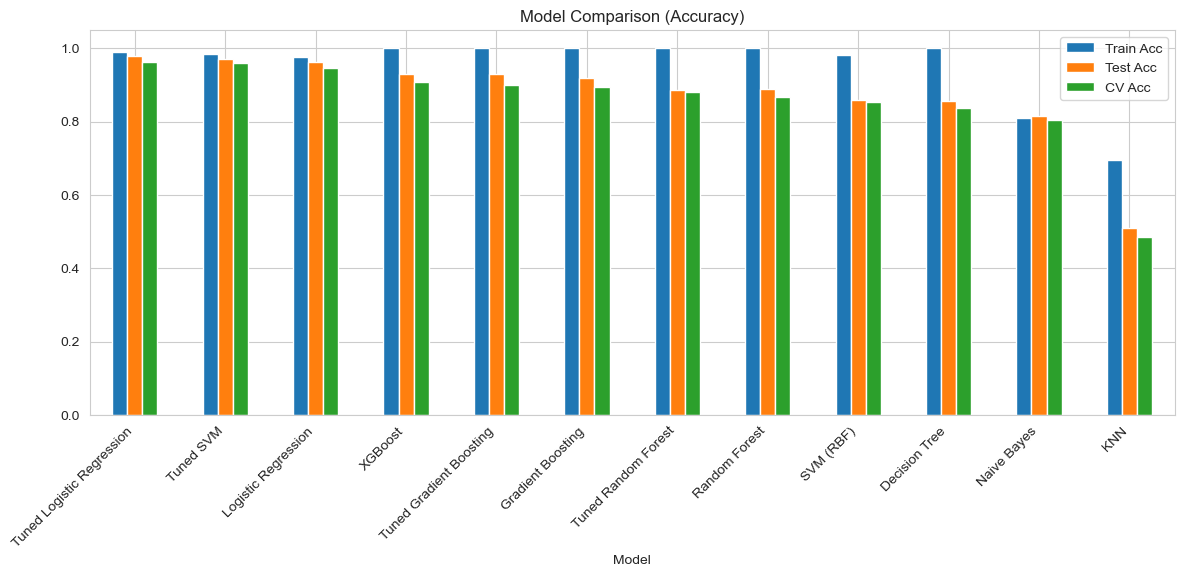

In [34]:
# Comparison chart
res_df.set_index("Model")[["Train Acc", "Test Acc", "CV Acc"]].plot(kind="bar", figsize=(14, 5))
plt.title("Model Comparison (Accuracy)")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.show()

Best model: Tuned Logistic Regression


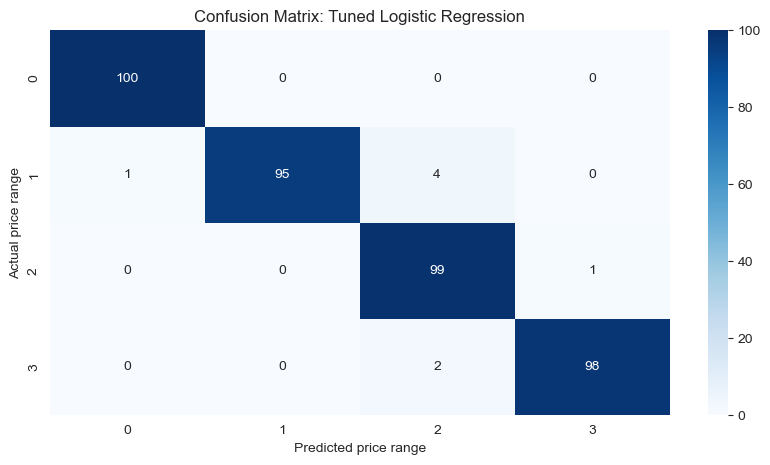

              precision    recall  f1-score   support

           0      0.990     1.000     0.995       100
           1      1.000     0.950     0.974       100
           2      0.943     0.990     0.966       100
           3      0.990     0.980     0.985       100

    accuracy                          0.980       400
   macro avg      0.981     0.980     0.980       400
weighted avg      0.981     0.980     0.980       400



In [35]:
# Confusion matrix of the best model
best_name  = res_df.loc[0, "Model"]
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)
print("Best model:", best_name)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
plt.xlabel("Predicted price range")
plt.ylabel("Actual price range")
plt.title(f"Confusion Matrix: {best_name}")
plt.show()

print(classification_report(y_test, y_pred, digits=3))

In [36]:
# The noise-feature experiment
from sklearn.base import clone

top5 = ["ram", "battery_power", "px_height", "px_width", "px_total"]

rows = []
for name in ["Logistic Regression", "Random Forest"]:
    m_all = clone(models[name]).fit(X_train, y_train)
    m_top = clone(models[name]).fit(X_train[top5], y_train)
    rows.append({
        "Model": name,
        "Test Acc (all 22 features)": accuracy_score(y_test, m_all.predict(X_test)),
        "Test Acc (top 5 features)":  accuracy_score(y_test, m_top.predict(X_test[top5])),
    })
pd.DataFrame(rows).round(3)

,Model,Test Acc (all 22 features),Test Acc (top 5 features)
0,Logistic Regression,0.962,0.968
1,Random Forest,0.888,0.952


## Model Comparison Report

### Models evaluated
Logistic Regression, KNN, SVM (RBF), Naive Bayes, Decision Tree, Random Forest,
Gradient Boosting and XGBoost, plus tuned versions of Logistic Regression, SVM,
Gradient Boosting and Random Forest. Metrics: accuracy, macro precision, recall, F1,
ROC-AUC and 5-fold stratified cross-validated accuracy.

### Results
(paste the res_df table here)

### Observations
- **Best model: Tuned Logistic Regression** (CV accuracy about 96.3%, test accuracy
  98.0%, macro F1 0.98, ROC-AUC 0.999).
- The tuned SVM (linear kernel) was a close second (CV about 96.0%).
- Tree-based models (Decision Tree, Random Forest, Gradient Boosting, XGBoost) reached
  100% training accuracy but lower test accuracy, which is **overfitting**.
- KNN performed worst (about 51%) because distance is dominated by uninformative features.
- Linear models win because price class rises almost linearly with RAM, battery and resolution.
- Removing noisy features improved Random Forest from 88.8% to 95.3%.
- All errors of the best model were between neighbouring price classes.

### Recommendation for production
**Tuned Logistic Regression.** Reasons: highest cross-validated accuracy, a small gap
between train and test (98.9% vs 98.0%), very fast training and prediction, and easy
interpretation: its coefficients show how each spec pushes the price range up or down,
which is exactly what Bob needs to understand his pricing.

### Limitations
The dataset is clean and the classes are very linearly separable; real market data
(brand, launch date, discounts) would be messier. The test set has 400 phones, so
differences of about 1% between top models are within noise.